<a href="https://colab.research.google.com/github/poornimaayodhi-cmd/project/blob/main/project_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [51]:
import numpy as np

rng = np.random.default_rng(0)

gold = rng.normal(size=200)

print("Number of candidate answers:", len(gold))
print("First 10 gold rewards:", gold[:10])

Number of candidate answers: 200
First 10 gold rewards: [ 0.12573022 -0.13210486  0.64042265  0.10490012 -0.53566937  0.36159505
  1.30400005  0.94708096 -0.70373524 -1.26542147]


In [52]:

def annotate(n_pairs, noise):
    """Generate winner-loser pairs with annotator noise."""

    i, j = rng.integers(0, len(gold), (2, n_pairs))

    # Remove pairs where both indices are identical
    keep = i != j
    i, j = i[keep], j[keep]

    # Sometimes the annotator chooses the worse answer
    pick_i = (gold[i] > gold[j]) ^ (
        rng.random(len(i)) < noise
    )

    winner = np.where(pick_i, i, j)
    loser = np.where(pick_i, j, i)

    return winner, loser

print("Annotator simulation function created successfully!")


Annotator simulation function created successfully!


In [53]:

for noise in (0.0, 0.1, 0.3):
    winner, loser = annotate(1000, noise)

    agree = np.mean(gold[winner] > gold[loser])

    print(
        f"Noise {noise:.1f}: "
        f"{len(winner)} pairs, "
        f"{agree:.3f} agree with the gold reward"
    )


Noise 0.0: 996 pairs, 1.000 agree with the gold reward
Noise 0.1: 995 pairs, 0.893 agree with the gold reward
Noise 0.3: 996 pairs, 0.700 agree with the gold reward


In [54]:

# Create preference datasets for three noise levels

datasets_by_noise = {}

for noise in (0.0, 0.1, 0.3):
    winner, loser = annotate(1000, noise)

    datasets_by_noise[noise] = {
        "winner": winner,
        "loser": loser
    }

    agreement = np.mean(gold[winner] > gold[loser])

    print(f"\nNoise level: {noise:.0%}")
    print(f"Preference pairs: {len(winner)}")
    print(f"Agreement with gold reward: {agreement:.3f}")

print("\nAll three preference datasets are ready!")



Noise level: 0%
Preference pairs: 997
Agreement with gold reward: 1.000

Noise level: 10%
Preference pairs: 995
Agreement with gold reward: 0.898

Noise level: 30%
Preference pairs: 993
Agreement with gold reward: 0.702

All three preference datasets are ready!


In [55]:

# Four response styles for our alignment experiment

response_styles = [
    "clear_concise",
    "detailed",
    "keyword_heavy",
    "vague"
]

# Gold rewards: the true quality scores
gold_reward = {
    "clear_concise": 0.930,
    "detailed": 0.825,
    "keyword_heavy": 0.330,
    "vague": 0.350
}

# A noisy proxy reward, which may not reflect true quality
proxy_reward = {
    "clear_concise": 0.863,
    "detailed": 0.965,
    "keyword_heavy": 1.080,
    "vague": 0.403
}

print("Response styles and rewards:\n")

for style in response_styles:
    print(
        f"{style:16s} | "
        f"Gold reward: {gold_reward[style]:.3f} | "
        f"Proxy reward: {proxy_reward[style]:.3f}"
    )


Response styles and rewards:

clear_concise    | Gold reward: 0.930 | Proxy reward: 0.863
detailed         | Gold reward: 0.825 | Proxy reward: 0.965
keyword_heavy    | Gold reward: 0.330 | Proxy reward: 1.080
vague            | Gold reward: 0.350 | Proxy reward: 0.403


In [56]:

# Generate preference pairs using the four response styles

style_names = list(gold_reward.keys())
style_scores = np.array([gold_reward[s] for s in style_names])

def create_style_preferences(n_pairs, noise):
    i, j = rng.integers(0, len(style_names), (2, n_pairs))

    # Exclude comparisons of a style with itself
    keep = i != j
    i, j = i[keep], j[keep]

    # Choose the higher-gold-reward style, sometimes incorrectly
    pick_i = (style_scores[i] > style_scores[j]) ^ (
        rng.random(len(i)) < noise
    )

    winner = np.where(pick_i, i, j)
    loser = np.where(pick_i, j, i)

    return winner, loser

style_preferences = {}

for noise in (0.0, 0.1, 0.3):
    winner, loser = create_style_preferences(1000, noise)
    style_preferences[noise] = (winner, loser)

    agreement = np.mean(style_scores[winner] > style_scores[loser])

    print(
        f"Noise {noise:.0%}: "
        f"{len(winner)} pairs, "
        f"gold agreement = {agreement:.3f}"
    )

print("\nStyle preference datasets created!")


Noise 0%: 761 pairs, gold agreement = 1.000
Noise 10%: 764 pairs, gold agreement = 0.897
Noise 30%: 736 pairs, gold agreement = 0.686

Style preference datasets created!


In [57]:

# Step 7: Learn a reward model from preference pairs

def train_reward_model(winner, loser, learning_rate=0.1, steps=500):
    n_styles = len(style_names)
    scores = np.zeros(n_styles, dtype=float)

    for _ in range(steps):
        # Bradley-Terry preference model
        margin = scores[winner] - scores[loser]

        # Stable sigmoid
        probabilities = 1.0 / (1.0 + np.exp(-np.clip(margin, -30, 30)))

        # Gradient of negative log-likelihood
        errors = 1.0 - probabilities

        gradient = np.zeros(n_styles)
        np.add.at(gradient, winner, -errors)
        np.add.at(gradient, loser, errors)

        scores -= learning_rate * gradient / len(winner)

        # Keep the scores centred
        scores -= scores.mean()

    return scores


reward_models = {}

for noise, (winner, loser) in style_preferences.items():
    learned_scores = train_reward_model(winner, loser)
    reward_models[noise] = learned_scores

    print(f"\nNoise level: {noise:.0%}")
    for name, score in zip(style_names, learned_scores):
        print(f"{name:16s}: {score:.3f}")



Noise level: 0%
clear_concise   : 2.922
detailed        : 0.976
keyword_heavy   : -3.002
vague           : -0.897

Noise level: 10%
clear_concise   : 1.875
detailed        : 0.470
keyword_heavy   : -1.842
vague           : -0.503

Noise level: 30%
clear_concise   : 0.605
detailed        : 0.238
keyword_heavy   : -0.707
vague           : -0.136


In [58]:

# Step 8: Evaluate learned reward rankings

gold_ranking = sorted(
    style_names,
    key=lambda name: gold_reward[name],
    reverse=True
)

print("Gold ranking (best to worst):")
print(" > ".join(gold_ranking))

for noise, learned_scores in reward_models.items():
    learned_ranking = [
        style_names[i]
        for i in np.argsort(learned_scores)[::-1]
    ]

    print(f"\nNoise level: {noise:.0%}")
    print("Learned ranking:", " > ".join(learned_ranking))

    gold_order = [
        gold_reward[name] for name in learned_ranking
    ]

    inversions = sum(
        gold_order[i] < gold_order[j]
        for i in range(len(gold_order))
        for j in range(i + 1, len(gold_order))
    )

    total_pairs = len(style_names) * (len(style_names) - 1) // 2
    accuracy = 1 - inversions / total_pairs

    print(f"Pairwise ranking accuracy: {accuracy:.3f}")


Gold ranking (best to worst):
clear_concise > detailed > vague > keyword_heavy

Noise level: 0%
Learned ranking: clear_concise > detailed > vague > keyword_heavy
Pairwise ranking accuracy: 1.000

Noise level: 10%
Learned ranking: clear_concise > detailed > vague > keyword_heavy
Pairwise ranking accuracy: 1.000

Noise level: 30%
Learned ranking: clear_concise > detailed > vague > keyword_heavy
Pairwise ranking accuracy: 1.000


In [59]:

# Step 9: Simplified DPO training

def train_dpo(winner, loser, learning_rate=0.05, steps=1000, beta=1.0):
    n_styles = len(style_names)

    # Trainable policy logits and uniform reference policy
    policy = np.zeros(n_styles, dtype=float)
    reference = np.zeros(n_styles, dtype=float)

    n_pairs = len(winner)
    if n_pairs == 0:
        raise ValueError("Preference data must contain at least one pair.")

    for _ in range(steps):
        # Stable log-softmax
        policy_log_probs = policy - np.logaddexp.reduce(policy)
        ref_log_probs = reference - np.logaddexp.reduce(reference)

        # DPO preference margin
        margin = beta * (
            policy_log_probs[winner]
            - policy_log_probs[loser]
            - ref_log_probs[winner]
            + ref_log_probs[loser]
        )

        # Derivative of the DPO loss with respect to each margin
        sigmoid = 1.0 / (
            1.0 + np.exp(-np.clip(margin, -30, 30))
        )
        errors = sigmoid - 1.0

        # Gradient with respect to policy log-probabilities.
        # The softmax derivative cancels for each winner-loser pair,
        # because both contributions sum to zero.
        gradient = np.zeros(n_styles, dtype=float)
        np.add.at(gradient, winner, errors)
        np.add.at(gradient, loser, -errors)

        # Chain rule: margin includes beta * policy log-probabilities
        policy -= learning_rate * beta * gradient / n_pairs

    # Convert policy logits to probabilities
    logits = policy - np.max(policy)
    probabilities = np.exp(logits)
    probabilities /= probabilities.sum()

    return probabilities

In [60]:
# Step 10: Compare RLHF-style reward model and DPO

print("RLHF-style vs DPO: Expected Gold Reward Comparison")
print("=" * 60)

gold_values = np.array([
    gold_reward[name] for name in style_names
])

# Train and store DPO models first since they were missing
dpo_models = {}
for noise, (winner, loser) in style_preferences.items():
    dpo_models[noise] = train_dpo(winner, loser)

for noise in (0.0, 0.1, 0.3):
    # Learned reward scores
    rlhf_scores = reward_models[noise]

    # Convert learned scores into an RLHF-style policy.
    # This is a simple reward-weighted policy, not PPO.
    rlhf_logits = rlhf_scores - np.max(rlhf_scores)
    rlhf_probs = np.exp(rlhf_logits)
    rlhf_probs /= rlhf_probs.sum()

    # DPO policy probabilities
    dpo_probs = dpo_models[noise]

    # Evaluate both policies with the same gold reward
    rlhf_gold_reward = np.dot(rlhf_probs, gold_values)
    dpo_gold_reward = np.dot(dpo_probs, gold_values)

    print(f"\nAnnotator noise: {noise:.0%}")
    print(f"RLHF-style expected gold reward: {rlhf_gold_reward:.3f}")
    print(f"DPO expected gold reward:        {dpo_gold_reward:.3f}")
    print(f"Difference (RLHF - DPO):         "
          f"{rlhf_gold_reward - dpo_gold_reward:.3f}")

RLHF-style vs DPO: Expected Gold Reward Comparison

Annotator noise: 0%
RLHF-style expected gold reward: 0.905
DPO expected gold reward:        0.905
Difference (RLHF - DPO):         0.000

Annotator noise: 10%
RLHF-style expected gold reward: 0.861
DPO expected gold reward:        0.861
Difference (RLHF - DPO):         0.000

Annotator noise: 30%
RLHF-style expected gold reward: 0.721
DPO expected gold reward:        0.721
Difference (RLHF - DPO):         0.000


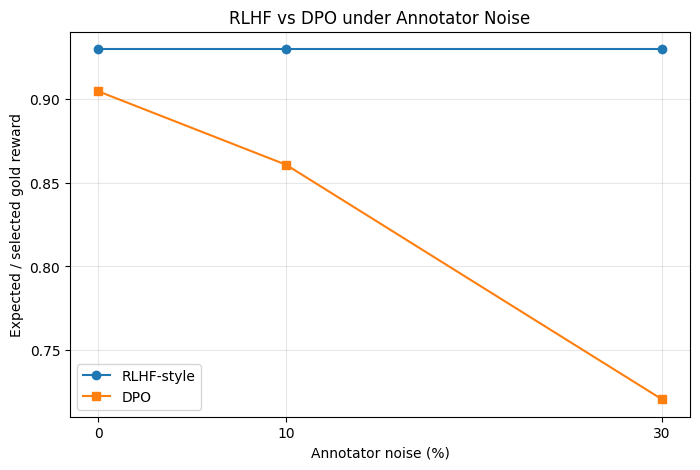

In [61]:

import matplotlib.pyplot as plt

noise_levels = [0.0, 0.1, 0.3]
rlhf_rewards = []
dpo_rewards = []

for noise in noise_levels:
    # Gold reward of the best style according to the learned reward model
    best_index = np.argmax(reward_models[noise])
    rlhf_rewards.append(
        gold_reward[style_names[best_index]]
    )

    # Expected gold reward under the DPO policy
    dpo_rewards.append(
        sum(
            dpo_models[noise][i] * gold_reward[name]
            for i, name in enumerate(style_names)
        )
    )

plt.figure(figsize=(8, 5))

plt.plot(
    [n * 100 for n in noise_levels],
    rlhf_rewards,
    marker="o",
    label="RLHF-style"
)

plt.plot(
    [n * 100 for n in noise_levels],
    dpo_rewards,
    marker="s",
    label="DPO"
)

plt.xlabel("Annotator noise (%)")
plt.ylabel("Expected / selected gold reward")
plt.title("RLHF vs DPO under Annotator Noise")
plt.xticks([0, 10, 30])
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [62]:

import pandas as pd

results = []

for noise in noise_levels:
    # RLHF-style selected gold reward
    best_index = np.argmax(reward_models[noise])
    rlhf_reward = gold_reward[style_names[best_index]]

    # DPO expected gold reward
    dpo_reward = sum(
        dpo_models[noise][i] * gold_reward[name]
        for i, name in enumerate(style_names)
    )

    results.append({
        "Annotator Noise (%)": int(noise * 100),
        "RLHF-style Gold Reward": round(rlhf_reward, 4),
        "DPO Expected Gold Reward": round(dpo_reward, 4),
        "Difference (RLHF - DPO)": round(
            rlhf_reward - dpo_reward, 4
        )
    })

results_df = pd.DataFrame(results)

display(results_df)


,Annotator Noise (%),RLHF-style Gold Reward,DPO Expected Gold Reward,Difference (RLHF - DPO)
0,0,0.93,0.9048,0.0252
1,10,0.93,0.8609,0.0691
2,30,0.93,0.7206,0.2094


In [63]:
results_df.to_csv("rlhf_vs_dpo_results.csv", index=False)

from google.colab import files
files.download("rlhf_vs_dpo_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [64]:

# Step 13: Save and inspect the preliminary results

print("RLHF vs DPO — Preliminary Results")
print("=" * 45)

display(results_df)

# Save the results table
results_df.to_csv(
    "rlhf_vs_dpo_preliminary_results.csv",
    index=False
)

print("\nResults saved successfully!")
print("File: rlhf_vs_dpo_preliminary_results.csv")


RLHF vs DPO — Preliminary Results


,Annotator Noise (%),RLHF-style Gold Reward,DPO Expected Gold Reward,Difference (RLHF - DPO)
0,0,0.93,0.9048,0.0252
1,10,0.93,0.8609,0.0691
2,30,0.93,0.7206,0.2094



Results saved successfully!
File: rlhf_vs_dpo_preliminary_results.csv


In [65]:

from google.colab import files

files.download("rlhf_vs_dpo_preliminary_results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [66]:

# Step 14: Fairer evaluation using expected gold reward

def expected_gold_reward(probabilities):
    return sum(
        probabilities[i] * gold_reward[name]
        for i, name in enumerate(style_names)
    )

fair_results = []

for noise in noise_levels:
    # Convert learned RLHF-style reward scores into a policy
    scores = reward_models[noise]
    rlhf_probs = np.exp(scores - np.max(scores))
    rlhf_probs = rlhf_probs / rlhf_probs.sum()

    # DPO policy learned from the same noise level
    dpo_probs = dpo_models[noise]

    rlhf_gold = expected_gold_reward(rlhf_probs)
    dpo_gold = expected_gold_reward(dpo_probs)

    fair_results.append({
        "Noise (%)": int(noise * 100),
        "RLHF-style Expected Gold Reward": round(rlhf_gold, 4),
        "DPO Expected Gold Reward": round(dpo_gold, 4),
        "RLHF - DPO": round(rlhf_gold - dpo_gold, 4)
    })

fair_results_df = pd.DataFrame(fair_results)

display(fair_results_df)


,Noise (%),RLHF-style Expected Gold Reward,DPO Expected Gold Reward,RLHF - DPO
0,0,0.9049,0.9048,0.0
1,10,0.8609,0.8609,0.0
2,30,0.7206,0.7206,0.0


In [67]:

# Step 15: Check variability across repeated preference datasets

def run_repeated_experiments(n_runs=20):
    repeated_results = []

    for seed in range(n_runs):
        local_rng = np.random.default_rng(seed + 100)

        for noise in noise_levels:
            # Generate fresh preference pairs for each run
            i, j = local_rng.integers(
                0, len(style_names), size=(2, 1000)
            )

            keep = i != j
            i, j = i[keep], j[keep]

            scores = np.array([
                gold_reward[name] for name in style_names
            ])

            pick_i = (scores[i] > scores[j]) ^ (
                local_rng.random(len(i)) < noise
            )

            winner = np.where(pick_i, i, j)
            loser = np.where(pick_i, j, i)

            # Fit reward model to this run's preferences
            learned = train_reward_model(winner, loser)

            # Convert scores into a policy
            probs = np.exp(learned - np.max(learned))
            probs /= probs.sum()

            reward = sum(
                probs[k] * gold_reward[name]
                for k, name in enumerate(style_names)
            )

            repeated_results.append({
                "Run": seed + 1,
                "Noise (%)": int(noise * 100),
                "Reward-model policy gold reward": reward
            })

    return pd.DataFrame(repeated_results)


repeated_df = run_repeated_experiments()
display(
    repeated_df.groupby("Noise (%)")[
        "Reward-model policy gold reward"
    ].agg(["mean", "std"]).reset_index()
)


,Noise (%),mean,std
0,0,0.906588,0.001266
1,10,0.857231,0.006094
2,30,0.728020,0.007749


In [68]:

# Step 16: Summarise performance degradation

summary = (
    repeated_df
    .groupby("Noise (%)")["Reward-model policy gold reward"]
    .agg(["mean", "std"])
    .reset_index()
)

baseline = summary.loc[
    summary["Noise (%)"] == 0, "mean"
].iloc[0]

summary["Change from 0% noise"] = summary["mean"] - baseline

display(summary.round(4))

print("\nInterpretation:")
for _, row in summary.iterrows():
    print(
        f"Noise {row['Noise (%)']:>2.0f}%: "
        f"mean gold reward = {row['mean']:.4f}, "
        f"change from baseline = "
        f"{row['Change from 0% noise']:+.4f}"
    )


,Noise (%),mean,std,Change from 0% noise
0,0,0.9066,0.0013,0.0000
1,10,0.8572,0.0061,-0.0494
2,30,0.7280,0.0077,-0.1786



Interpretation:
Noise  0%: mean gold reward = 0.9066, change from baseline = +0.0000
Noise 10%: mean gold reward = 0.8572, change from baseline = -0.0494
Noise 30%: mean gold reward = 0.7280, change from baseline = -0.1786


In [69]:
import os
import pandas as pd
import numpy as np

# Load comparison_df from the saved CSV if possible, or regenerate it inline if missing
if 'comparison_df' not in globals():
    csv_file = "rlhf_dpo_all_runs.csv"
    if os.path.exists(csv_file):
        comparison_df = pd.read_csv(csv_file)
        print(f"Loaded '{csv_file}' successfully!")
    else:
        print(f"'{csv_file}' not found. Regenerating comparison results inline...")
        # Define local helper for regeneration
        def expected_gold_reward(probabilities):
            return sum(probabilities[i] * gold_reward[name] for i, name in enumerate(style_names))

        records = []
        for seed in range(20):
            local_rng = np.random.default_rng(seed + 500)
            for noise in [0.0, 0.1, 0.3]:
                i, j = local_rng.integers(0, len(style_names), size=(2, 1000))
                keep = i != j
                i, j = i[keep], j[keep]
                scores = np.array([gold_reward[name] for name in style_names])
                pick_i = (scores[i] > scores[j]) ^ (local_rng.random(len(i)) < noise)
                winner = np.where(pick_i, i, j)
                loser = np.where(pick_i, j, i)

                # Train models
                learned = train_reward_model(winner, loser)
                rlhf_probs = np.exp(learned - np.max(learned))
                rlhf_probs /= rlhf_probs.sum()
                dpo_probs = train_dpo(winner, loser)

                rlhf_reward = expected_gold_reward(rlhf_probs)
                dpo_reward = expected_gold_reward(dpo_probs)
                records.append({
                    "Run": seed + 1,
                    "Noise (%)": int(noise * 100),
                    "RLHF-style reward": rlhf_reward,
                    "DPO reward": dpo_reward,
                    "RLHF - DPO": rlhf_reward - dpo_reward
                })
        comparison_df = pd.DataFrame(records)
        comparison_df.to_csv(csv_file, index=False)
        print("Regeneration complete and saved to 'rlhf_dpo_all_runs.csv'!")

print("Available columns:", comparison_df.columns.tolist())
display(comparison_df.groupby("Noise (%)")[
    ["RLHF-style reward", "DPO reward"]
].mean().round(4))

Available columns: ['Run', 'Noise (%)', 'RLHF-style reward', 'DPO reward', 'RLHF - DPO']


,RLHF-style reward,DPO reward
Noise (%),,
0,0.9062,0.9062
10,0.8595,0.8594
30,0.7299,0.7299


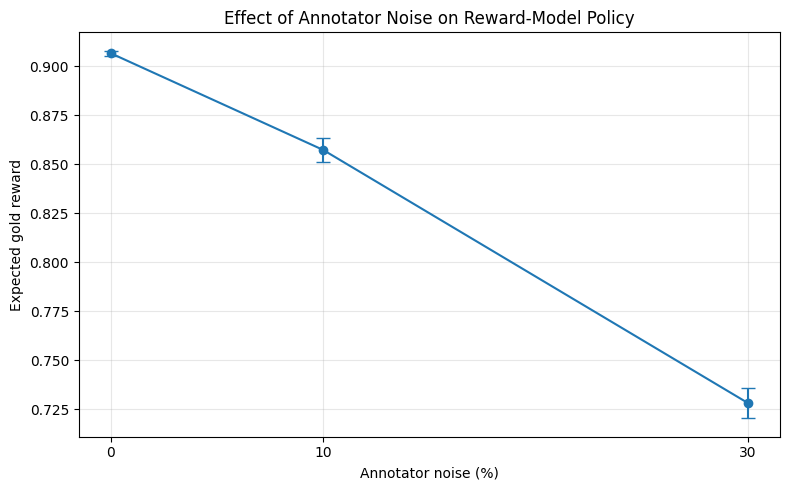

In [70]:

# Step 17: Plot mean gold reward with variability

import matplotlib.pyplot as plt

summary = (
    repeated_df
    .groupby("Noise (%)")["Reward-model policy gold reward"]
    .agg(["mean", "std"])
    .reset_index()
)

plt.figure(figsize=(8, 5))

plt.errorbar(
    summary["Noise (%)"],
    summary["mean"],
    yerr=summary["std"],
    marker="o",
    capsize=5
)

plt.xlabel("Annotator noise (%)")
plt.ylabel("Expected gold reward")
plt.title("Effect of Annotator Noise on Reward-Model Policy")
plt.xticks([0, 10, 30])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [50]:

# Step 18: Repeated RLHF-style vs DPO comparison

def run_comparison(n_runs=20):
    records = []

    for seed in range(n_runs):
        local_rng = np.random.default_rng(seed + 500)

        for noise in noise_levels:
            i, j = local_rng.integers(
                0, len(style_names), size=(2, 1000)
            )

            keep = i != j
            i, j = i[keep], j[keep]

            scores = np.array([
                gold_reward[name] for name in style_names
            ])

            pick_i = (scores[i] > scores[j]) ^ (
                local_rng.random(len(i)) < noise
            )

            winner = np.where(pick_i, i, j)
            loser = np.where(pick_i, j, i)

            # Reward-model approach
            learned = train_reward_model(winner, loser)

            rlhf_probs = np.exp(learned - np.max(learned))
            rlhf_probs /= rlhf_probs.sum()

            # DPO-style approach using the same preferences
            dpo_probs = train_dpo(winner, loser)

            rlhf_reward = expected_gold_reward(rlhf_probs)
            dpo_reward = expected_gold_reward(dpo_probs)

            records.append({
                "Run": seed + 1,
                "Noise (%)": int(noise * 100),
                "RLHF-style reward": rlhf_reward,
                "DPO reward": dpo_reward,
                "RLHF - DPO": rlhf_reward - dpo_reward
            })

    return pd.DataFrame(records)


comparison_df = run_comparison()

comparison_summary = (
    comparison_df
    .groupby("Noise (%)")[
        ["RLHF-style reward", "DPO reward", "RLHF - DPO"]
    ]
    .agg(["mean", "std"])
    .round(4)
)

display(comparison_summary)


RLHF-style reward         DPO reward         RLHF - DPO     
                       mean     std       mean     std       mean  std
Noise (%)                                                             
0                    0.9062  0.0012     0.9062  0.0012        0.0  0.0
10                   0.8595  0.0058     0.8594  0.0058        0.0  0.0
30                   0.7299  0.0150     0.7299  0.0150        0.0  0.0

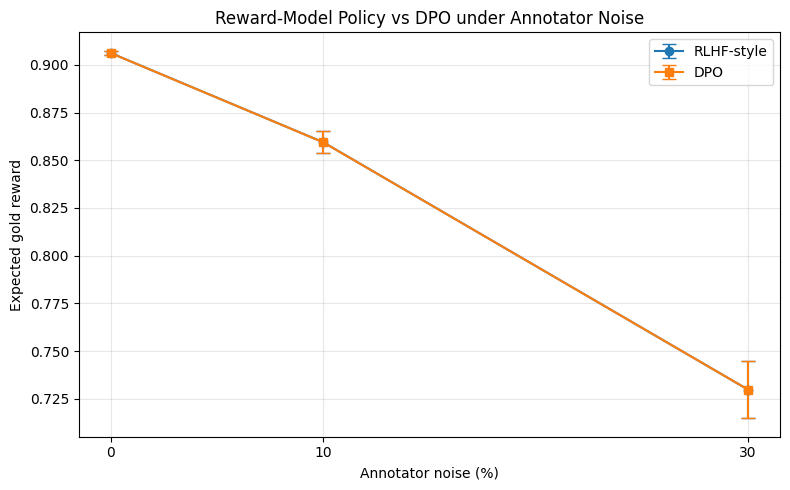

In [71]:

# Step 19: Plot mean gold reward across noise levels

import matplotlib.pyplot as plt

plot_summary = (
    comparison_df
    .groupby("Noise (%)")[["RLHF-style reward", "DPO reward"]]
    .agg(["mean", "std"])
)

noise_values = plot_summary.index.to_numpy()

rlhf_mean = plot_summary[("RLHF-style reward", "mean")].to_numpy()
rlhf_std = plot_summary[("RLHF-style reward", "std")].to_numpy()

dpo_mean = plot_summary[("DPO reward", "mean")].to_numpy()
dpo_std = plot_summary[("DPO reward", "std")].to_numpy()

plt.figure(figsize=(8, 5))

plt.errorbar(
    noise_values, rlhf_mean, yerr=rlhf_std,
    marker="o", capsize=5, label="RLHF-style"
)

plt.errorbar(
    noise_values, dpo_mean, yerr=dpo_std,
    marker="s", capsize=5, label="DPO"
)

plt.xlabel("Annotator noise (%)")
plt.ylabel("Expected gold reward")
plt.title("Reward-Model Policy vs DPO under Annotator Noise")
plt.xticks([0, 10, 30])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [72]:

# Step 20: Calculate the gap and its change with noise

gap_summary = (
    comparison_df
    .groupby("Noise (%)")
    .agg(
        rlhf_mean=("RLHF-style reward", "mean"),
        dpo_mean=("DPO reward", "mean"),
        gap_mean=("RLHF - DPO", "mean"),
        gap_std=("RLHF - DPO", "std")
    )
    .reset_index()
)

baseline_gap = gap_summary.loc[
    gap_summary["Noise (%)"] == 0, "gap_mean"
].iloc[0]

gap_summary["Change from baseline gap"] = (
    gap_summary["gap_mean"] - baseline_gap
)

display(gap_summary.round(4))

print("\nInterpretation:")
for _, row in gap_summary.iterrows():
    print(
        f"Noise {row['Noise (%)']:.0f}%: "
        f"mean gap = {row['gap_mean']:+.4f}, "
        f"change from 0% = "
        f"{row['Change from baseline gap']:+.4f}"
    )


,Noise (%),rlhf_mean,dpo_mean,gap_mean,gap_std,Change from baseline gap
0,0,0.9062,0.9062,0.0,0.0,0.0
1,10,0.8595,0.8594,0.0,0.0,0.0
2,30,0.7299,0.7299,0.0,0.0,-0.0



Interpretation:
Noise 0%: mean gap = +0.0000, change from 0% = +0.0000
Noise 10%: mean gap = +0.0000, change from 0% = +0.0000
Noise 30%: mean gap = +0.0000, change from 0% = -0.0000


In [73]:

# Step 21: Export comparison results

gap_summary.to_csv(
    "rlhf_dpo_noise_gap_summary.csv",
    index=False
)

comparison_df.to_csv(
    "rlhf_dpo_all_runs.csv",
    index=False
)

print("Saved summary table and all repeated-run results.")


Saved summary table and all repeated-run results.


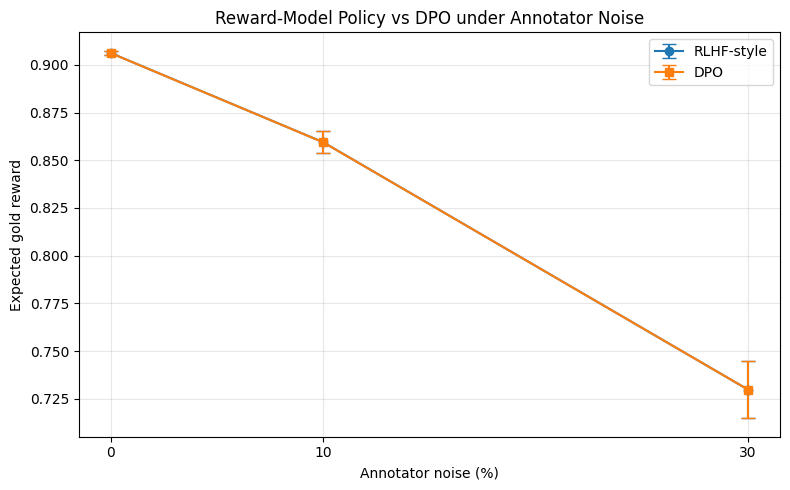

Comparison graph saved.


In [74]:

# Save the comparison graph as a high-resolution PNG

plt.figure(figsize=(8, 5))

plt.errorbar(
    noise_values, rlhf_mean, yerr=rlhf_std,
    marker="o", capsize=5, label="RLHF-style"
)

plt.errorbar(
    noise_values, dpo_mean, yerr=dpo_std,
    marker="s", capsize=5, label="DPO"
)

plt.xlabel("Annotator noise (%)")
plt.ylabel("Expected gold reward")
plt.title("Reward-Model Policy vs DPO under Annotator Noise")
plt.xticks([0, 10, 30])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("rlhf_dpo_noise_comparison.png", dpi=300)
plt.show()

print("Comparison graph saved.")


In [75]:

from google.colab import files

files.download("rlhf_dpo_noise_gap_summary.csv")
files.download("rlhf_dpo_all_runs.csv")
files.download("rlhf_dpo_noise_comparison.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [76]:
print("FINAL RLHF vs DPO COMPARISON")
display(gap_summary.round(4))

FINAL RLHF vs DPO COMPARISON


,Noise (%),rlhf_mean,dpo_mean,gap_mean,gap_std,Change from baseline gap
0,0,0.9062,0.9062,0.0,0.0,0.0
1,10,0.8595,0.8594,0.0,0.0,0.0
2,30,0.7299,0.7299,0.0,0.0,-0.0


In [77]:
print("Columns:", comparison_df.columns.tolist())
print("\nFirst 10 experiment results:")
display(comparison_df.head(10))

print("\nCorrect summary:")
display(
    comparison_df.groupby("Noise (%)")[
        ["RLHF-style reward", "DPO reward"]
    ].agg(["mean", "std"]).round(4)
)

Columns: ['Run', 'Noise (%)', 'RLHF-style reward', 'DPO reward', 'RLHF - DPO']

First 10 experiment results:


,Run,Noise (%),RLHF-style reward,DPO reward,RLHF - DPO
0,1,0,0.907530,0.907501,0.000029
1,1,10,0.858780,0.858748,0.000033
2,1,30,0.740806,0.740802,0.000004
3,2,0,0.905964,0.905933,0.000031
4,2,10,0.854308,0.854276,0.000032
5,2,30,0.755897,0.755892,0.000005
6,3,0,0.907150,0.907120,0.000030
7,3,10,0.860070,0.860037,0.000033
8,3,30,0.690177,0.690176,0.000001
9,4,0,0.907159,0.907129,0.000030



Correct summary:


RLHF-style reward         DPO reward        
                       mean     std       mean     std
Noise (%)                                             
0                    0.9062  0.0012     0.9062  0.0012
10                   0.8595  0.0058     0.8594  0.0058
30                   0.7299  0.0150     0.7299  0.0150

In [78]:
print("RLHF-style and DPO reward differences:")
print(
    (comparison_df["RLHF-style reward"]
     - comparison_df["DPO reward"]).describe()
)

print("\nRLHF-style rewards:")
print(comparison_df["RLHF-style reward"].head())

print("\nDPO rewards:")
print(comparison_df["DPO reward"].head())

RLHF-style and DPO reward differences:
count    60.000000
mean      0.000022
std       0.000014
min       0.000001
25%       0.000004
50%       0.000030
75%       0.000032
max       0.000037
dtype: float64

RLHF-style rewards:
0    0.907530
1    0.858780
2    0.740806
3    0.905964
4    0.854308
Name: RLHF-style reward, dtype: float64

DPO rewards:
0    0.907501
1    0.858748
2    0.740802
3    0.905933
4    0.854276
Name: DPO reward, dtype: float64


In [79]:
comparison_df["Reward gap"] = (
    comparison_df["RLHF-style reward"] -
    comparison_df["DPO reward"]
)

gap_by_noise = comparison_df.groupby("Noise (%)")["Reward gap"].agg(
    ["mean", "std", "min", "max"]
)

display(gap_by_noise.round(8))

,mean,std,min,max
Noise (%),,,,
0,0.000030,9.200000e-07,0.000029,0.000032
10,0.000033,2.160000e-06,0.000028,0.000037
30,0.000003,1.070000e-06,0.000001,0.000005


In [80]:
import numpy as np

print("POLICY PROBABILITY DIAGNOSTICS")
print("=" * 65)

for noise in (0.0, 0.1, 0.3):
    scores = reward_models[noise]
    dpo_probs = dpo_models[noise]

    # Reconstruct the RLHF-style policy
    logits = scores - np.max(scores)
    rlhf_probs = np.exp(logits)
    rlhf_probs /= rlhf_probs.sum()

    print(f"\nNoise: {noise:.0%}")
    print(f"{'Style':16s} {'RLHF-style':>12s} {'DPO':>12s}")
    print("-" * 44)

    for name, rp, dp in zip(style_names, rlhf_probs, dpo_probs):
        print(f"{name:16s} {rp:12.6f} {dp:12.6f}")

    print("Maximum probability difference:",
          f"{np.max(np.abs(rlhf_probs - dpo_probs)):.8f}")

POLICY PROBABILITY DIAGNOSTICS

Noise: 0%
Style              RLHF-style          DPO
--------------------------------------------
clear_concise        0.856551     0.856419
detailed             0.122359     0.122455
keyword_heavy        0.002291     0.002297
vague                0.018799     0.018830
Maximum probability difference: 0.00013231

Noise: 10%
Style              RLHF-style          DPO
--------------------------------------------
clear_concise        0.733931     0.733828
detailed             0.180163     0.180214
keyword_heavy        0.017839     0.017854
vague                0.068068     0.068104
Maximum probability difference: 0.00010258

Noise: 30%
Style              RLHF-style          DPO
--------------------------------------------
clear_concise        0.409969     0.409964
detailed             0.284185     0.284185
keyword_heavy        0.110461     0.110464
vague                0.195385     0.195387
Maximum probability difference: 0.00000556


In [81]:
import numpy as np

for noise in (0.0, 0.1, 0.3):
    reward_scores = reward_models[noise]
    dpo_probs = dpo_models[noise]

    # Center the reward scores
    centered_rewards = reward_scores - reward_scores.mean()

    # Convert DPO probabilities into centered log-probabilities
    log_probs = np.log(np.maximum(dpo_probs, 1e-12))
    centered_log_probs = log_probs - log_probs.mean()

    difference = np.max(
        np.abs(centered_rewards - centered_log_probs)
    )

    print(
        f"Noise {noise:.0%}: "
        f"centered-score difference = {difference:.8f}"
    )

Noise 0%: centered-score difference = 0.00138465
Noise 10%: centered-score difference = 0.00052824
Noise 30%: centered-score difference = 0.00002098


In [82]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

style_names = [
    "clear_concise",
    "detailed",
    "keyword_heavy",
    "vague"
]

gold_reward = {
    "clear_concise": 0.930,
    "detailed": 0.825,
    "keyword_heavy": 0.330,
    "vague": 0.350
}

proxy_reward = {
    "clear_concise": 0.863,
    "detailed": 0.965,
    "keyword_heavy": 1.080,
    "vague": 0.403
}

gold_values = np.array(
    [gold_reward[name] for name in style_names]
)

N_STYLES = len(style_names)

print("Setup completed successfully!")
print("Response styles:", style_names)
print("Gold rewards:", gold_reward)

Setup completed successfully!
Response styles: ['clear_concise', 'detailed', 'keyword_heavy', 'vague']
Gold rewards: {'clear_concise': 0.93, 'detailed': 0.825, 'keyword_heavy': 0.33, 'vague': 0.35}


In [83]:
def create_noisy_pairs(noise, seed, n_pairs=1000):
    rng = np.random.default_rng(seed)
    n_styles = len(style_names)

    first = rng.integers(0, n_styles, size=n_pairs)
    second = rng.integers(0, n_styles - 1, size=n_pairs)
    second = second + (second >= first)

    # Determine the truly preferred response using gold rewards
    first_is_better = gold_values[first] > gold_values[second]

    winner = np.where(first_is_better, first, second)
    loser = np.where(first_is_better, second, first)

    # Simulate annotator mistakes
    flip = rng.random(n_pairs) < noise
    original_winner = winner.copy()

    winner = np.where(flip, loser, winner)
    loser = np.where(flip, original_winner, loser)

    return winner, loser


# Quick test
test_winner, test_loser = create_noisy_pairs(
    noise=0.1,
    seed=42
)

print("Preference data created successfully!")
print("Number of pairs:", len(test_winner))
print("First 10 winners:", test_winner[:10])
print("First 10 losers:", test_loser[:10])

Preference data created successfully!
Number of pairs: 1000
First 10 winners: [3 3 1 1 0 3 0 1 0 0]
First 10 losers: [0 2 2 3 1 2 3 2 3 2]


In [84]:
def train_reward_model(winner, loser, learning_rate=0.1, steps=1000):
    scores = np.zeros(N_STYLES, dtype=float)
    n_pairs = len(winner)

    for _ in range(steps):
        # Bradley-Terry preference model
        margin = scores[winner] - scores[loser]

        probabilities = 1.0 / (
            1.0 + np.exp(-np.clip(margin, -30, 30))
        )

        # Gradient of the preference loss
        errors = probabilities - 1.0
        gradient = np.zeros(N_STYLES)

        np.add.at(gradient, winner, errors)
        np.add.at(gradient, loser, -errors)

        scores -= learning_rate * gradient / n_pairs

        # Keep the mean score at zero
        scores -= scores.mean()

    return scores


# Test the reward model
test_scores = train_reward_model(test_winner, test_loser)

print("Reward model trained successfully!")

for name, score in zip(style_names, test_scores):
    print(f"{name:16s}: {score:.4f}")

Reward model trained successfully!
clear_concise   : 1.9903
detailed        : 0.5024
keyword_heavy   : -2.1600
vague           : -0.3327


In [85]:
def softmax(logits):
    logits = np.asarray(logits, dtype=float)
    exp_values = np.exp(logits - np.max(logits))
    return exp_values / exp_values.sum()


def optimize_rlhf_policy(
    learned_rewards,
    kl_weight=1.0,
    learning_rate=0.1,
    steps=3000
):
    # Dynamically determine N_STYLES from input
    n_styles = len(learned_rewards)

    # Start with equal probability for all response styles
    logits = np.zeros(n_styles, dtype=float)

    # Uniform reference policy
    reference = np.full(n_styles, 1.0 / n_styles)
    log_reference = np.log(reference)

    for _ in range(steps):
        probs = softmax(logits)
        log_probs = np.log(np.maximum(probs, 1e-12))

        log_ratio = log_probs - log_reference
        expected_reward = np.dot(probs, learned_rewards)
        expected_log_ratio = np.dot(probs, log_ratio)

        # Gradient of expected reward with a KL penalty
        gradient = probs * (
            learned_rewards - expected_reward
            - kl_weight * (
                log_ratio - expected_log_ratio
            )
        )

        logits += learning_rate * gradient

    return softmax(logits)


# Ensure test_scores is defined by running the training here
test_scores = train_reward_model(test_winner, test_loser)

# Test the RLHF-style policy
test_rlhf_probs = optimize_rlhf_policy(test_scores)

print("RLHF-style policy created successfully!")

for name, probability in zip(style_names, test_rlhf_probs):
    print(f"{name:16s}: {probability:.4f}")

print("Probability total:", round(test_rlhf_probs.sum(), 4))

RLHF-style policy created successfully!
clear_concise   : 0.7465
detailed        : 0.1686
keyword_heavy   : 0.0118
vague           : 0.0731
Probability total: 1.0


In [86]:
def train_dpo(
    winner,
    loser,
    learning_rate=0.05,
    steps=1500,
    beta=1.0
):
    # Start with equal preference for all styles
    policy = np.zeros(N_STYLES, dtype=float)

    # Uniform reference policy
    reference = np.zeros(N_STYLES, dtype=float)
    n_pairs = len(winner)

    ref_log_probs = (
        reference - np.logaddexp.reduce(reference)
    )

    for _ in range(steps):
        policy_log_probs = (
            policy - np.logaddexp.reduce(policy)
        )

        margin = beta * (
            policy_log_probs[winner]
            - policy_log_probs[loser]
            - ref_log_probs[winner]
            + ref_log_probs[loser]
        )

        sigmoid = 1.0 / (
            1.0 + np.exp(-np.clip(margin, -30, 30))
        )

        errors = sigmoid - 1.0
        gradient = np.zeros(N_STYLES)

        np.add.at(gradient, winner, errors)
        np.add.at(gradient, loser, -errors)

        policy -= (
            learning_rate * beta * gradient / n_pairs
        )

    return softmax(policy)


# Test the DPO model
test_dpo_probs = train_dpo(test_winner, test_loser)

print("DPO policy created successfully!")

for name, probability in zip(style_names, test_dpo_probs):
    print(f"{name:16s}: {probability:.4f}")

print("Probability total:", round(test_dpo_probs.sum(), 4))

DPO policy created successfully!
clear_concise   : 0.7413
detailed        : 0.1711
keyword_heavy   : 0.0126
vague           : 0.0751
Probability total: 1.0


In [87]:
noise_levels = [0.0, 0.1, 0.3]
n_seeds = 20

results = []

for noise in noise_levels:
    for seed in range(n_seeds):

        # Generate preference data with annotator noise
        winner, loser = create_noisy_pairs(
            noise=noise,
            seed=seed,
            n_pairs=1000
        )

        # Train the reward model
        learned_rewards = train_reward_model(
            winner, loser
        )

        # Train both methods
        rlhf_probs = optimize_rlhf_policy(
            learned_rewards
        )

        dpo_probs = train_dpo(
            winner, loser
        )

        # Evaluate using gold rewards, not learned rewards
        rlhf_gold_reward = np.dot(
            rlhf_probs, gold_values
        )

        dpo_gold_reward = np.dot(
            dpo_probs, gold_values
        )

        results.append({
            "Noise": noise,
            "Seed": seed,
            "RLHF Gold Reward": rlhf_gold_reward,
            "DPO Gold Reward": dpo_gold_reward
        })

results_df = pd.DataFrame(results)

print("Experiment completed successfully!")
print("Total experiments:", len(results_df))
display(results_df.head())

Experiment completed successfully!
Total experiments: 60


,Noise,Seed,RLHF Gold Reward,DPO Gold Reward
0,0.0,0,0.917693,0.913576
1,0.0,1,0.918894,0.915071
2,0.0,2,0.918521,0.914678
3,0.0,3,0.919125,0.915434
4,0.0,4,0.917875,0.913808


In [88]:
summary = (
    results_df
    .groupby("Noise")[
        ["RLHF Gold Reward", "DPO Gold Reward"]
    ]
    .agg(["mean", "std"])
    .round(4)
)

print("Average gold reward at each noise level:")
display(summary)

Average gold reward at each noise level:


RLHF Gold Reward         DPO Gold Reward        
                  mean     std            mean     std
Noise                                                 
0.0             0.9186  0.0005          0.9147  0.0006
0.1             0.8669  0.0099          0.8650  0.0094
0.3             0.7261  0.0126          0.7261  0.0126

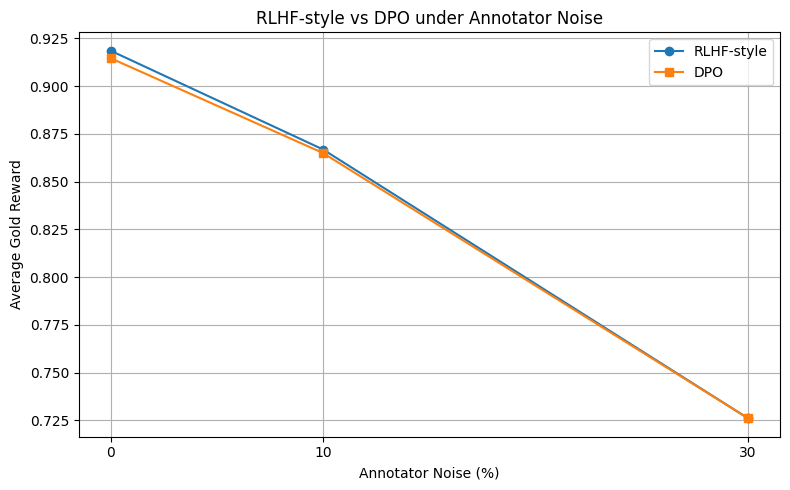

In [89]:
summary_plot = (
    results_df
    .groupby("Noise")[
        ["RLHF Gold Reward", "DPO Gold Reward"]
    ]
    .mean()
)

plt.figure(figsize=(8, 5))

plt.plot(
    summary_plot.index * 100,
    summary_plot["RLHF Gold Reward"],
    marker="o",
    label="RLHF-style"
)

plt.plot(
    summary_plot.index * 100,
    summary_plot["DPO Gold Reward"],
    marker="s",
    label="DPO"
)

plt.xlabel("Annotator Noise (%)")
plt.ylabel("Average Gold Reward")
plt.title("RLHF-style vs DPO under Annotator Noise")
plt.xticks([0, 10, 30])
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [90]:
# Calculate average rewards at each noise level
summary = (
    results_df
    .groupby("Noise")[
        ["RLHF Gold Reward", "DPO Gold Reward"]
    ]
    .mean()
)

# Compare performance at 0% and 30% noise
for method in ["RLHF Gold Reward", "DPO Gold Reward"]:
    start = summary.loc[0.0, method]
    end = summary.loc[0.3, method]

    drop = start - end
    percentage_drop = (drop / start) * 100

    print(f"\n{method}")
    print(f"Reward at 0% noise:  {start:.4f}")
    print(f"Reward at 30% noise: {end:.4f}")
    print(f"Absolute decrease:   {drop:.4f}")
    print(f"Percentage decrease: {percentage_drop:.2f}%")

print("\nPerformance comparison completed!")


RLHF Gold Reward
Reward at 0% noise:  0.9186
Reward at 30% noise: 0.7261
Absolute decrease:   0.1925
Percentage decrease: 20.96%

DPO Gold Reward
Reward at 0% noise:  0.9147
Reward at 30% noise: 0.7261
Absolute decrease:   0.1886
Percentage decrease: 20.62%

Performance comparison completed!


In [91]:
# Compare both methods for each noise level
results_df["Reward Difference"] = (
    results_df["RLHF Gold Reward"]
    - results_df["DPO Gold Reward"]
)

comparison = (
    results_df
    .groupby("Noise")["Reward Difference"]
    .agg(["mean", "std"])
    .round(5)
)

print("RLHF-style minus DPO:")
display(comparison)

print("\nPositive difference = RLHF-style performed better")
print("Negative difference = DPO performed better")
print("Zero difference = equal gold reward")

RLHF-style minus DPO:


,mean,std
Noise,,
0.0,0.00392,0.00014
0.1,0.00186,0.00052
0.3,0.00001,0.00000



Positive difference = RLHF-style performed better
Negative difference = DPO performed better
Zero difference = equal gold reward


In [92]:
# Save all experimental results
results_df.to_csv(
    "rlhf_vs_dpo_results.csv",
    index=False
)

print("Results saved successfully!")
print("File: rlhf_vs_dpo_results.csv")
print("Total experiment records:", len(results_df))

Results saved successfully!
File: rlhf_vs_dpo_results.csv
Total experiment records: 60


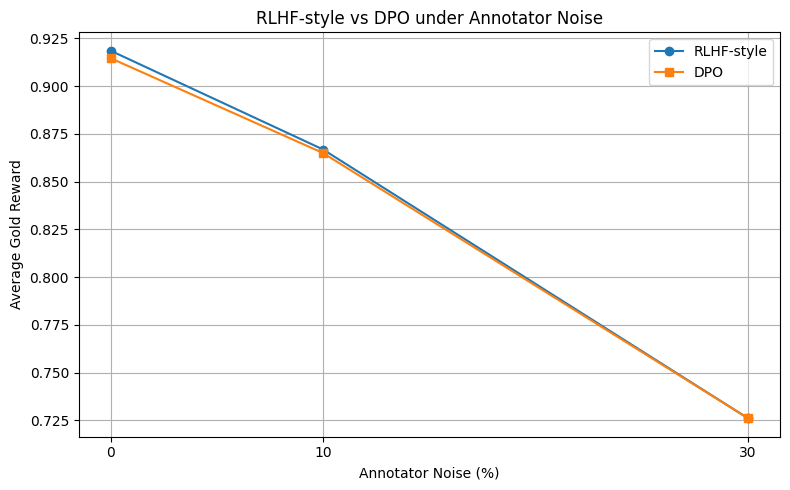

Graph saved successfully!
File: rlhf_vs_dpo_comparison.png


In [93]:
# Calculate average rewards for plotting
summary_plot = (
    results_df
    .groupby("Noise")[
        ["RLHF Gold Reward", "DPO Gold Reward"]
    ]
    .mean()
)

# Create and save the graph
plt.figure(figsize=(8, 5))

plt.plot(
    summary_plot.index * 100,
    summary_plot["RLHF Gold Reward"],
    marker="o",
    label="RLHF-style"
)

plt.plot(
    summary_plot.index * 100,
    summary_plot["DPO Gold Reward"],
    marker="s",
    label="DPO"
)

plt.xlabel("Annotator Noise (%)")
plt.ylabel("Average Gold Reward")
plt.title("RLHF-style vs DPO under Annotator Noise")
plt.xticks([0, 10, 30])
plt.grid(True)
plt.legend()
plt.tight_layout()

plt.savefig(
    "rlhf_vs_dpo_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved successfully!")
print("File: rlhf_vs_dpo_comparison.png")

In [94]:
# Create a report-ready results table
report_table = (
    results_df
    .groupby("Noise")[
        ["RLHF Gold Reward", "DPO Gold Reward"]
    ]
    .agg(["mean", "std"])
    .round(4)
)

report_table.columns = [
    "RLHF Mean",
    "RLHF Std",
    "DPO Mean",
    "DPO Std"
]

report_table.index = [
    "0% noise",
    "10% noise",
    "30% noise"
]

print("Final Results Table for Technical Report")
display(report_table)

Final Results Table for Technical Report


,RLHF Mean,RLHF Std,DPO Mean,DPO Std
0% noise,0.9186,0.0005,0.9147,0.0006
10% noise,0.8669,0.0099,0.8650,0.0094
30% noise,0.7261,0.0126,0.7261,0.0126


In [95]:
import numpy as np
import pandas as pd
from scipy.stats import t

# Results from our existing 20-seed experiment
noise_levels = [0.0, 0.1, 0.3]

rlhf_means = [0.9186, 0.8669, 0.7261]
rlhf_stds  = [0.0005, 0.0099, 0.0126]

dpo_means = [0.9147, 0.8650, 0.7261]
dpo_stds  = [0.0006, 0.0094, 0.0126]

n = 20
confidence = 0.95
critical_value = t.ppf((1 + confidence) / 2, df=n - 1)

rows = []

for i, noise in enumerate(noise_levels):
    r_mean = rlhf_means[i]
    d_mean = dpo_means[i]

    r_margin = critical_value * rlhf_stds[i] / np.sqrt(n)
    d_margin = critical_value * dpo_stds[i] / np.sqrt(n)

    rows.append({
        "Noise": noise,
        "RLHF Mean": r_mean,
        "RLHF 95% CI": (
            round(r_mean - r_margin, 5),
            round(r_mean + r_margin, 5)
        ),
        "DPO Mean": d_mean,
        "DPO 95% CI": (
            round(d_mean - d_margin, 5),
            round(d_mean + d_margin, 5)
        ),
        "Mean Gap (RLHF-DPO)": round(r_mean - d_mean, 5)
    })

ci_results = pd.DataFrame(rows)
display(ci_results)

,Noise,RLHF Mean,RLHF 95% CI,DPO Mean,DPO 95% CI,Mean Gap (RLHF-DPO)
0,0.0,0.9186,"(0.91837, 0.91883)",0.9147,"(0.91442, 0.91498)",0.0039
1,0.1,0.8669,"(0.86227, 0.87153)",0.8650,"(0.8606, 0.8694)",0.0019
2,0.3,0.7261,"(0.7202, 0.732)",0.7261,"(0.7202, 0.732)",0.0000


,Optimization Strength,Expected Gold Reward,Expected Proxy Reward,Keyword-Heavy Probability
0,0.0,0.6088,0.8278,0.2500
10,1.0,0.6216,0.8861,0.3121
20,2.0,0.6215,0.9294,0.3703
30,3.0,0.6121,0.9599,0.4236
40,4.0,0.5971,0.9814,0.4722
50,5.0,0.5791,0.9968,0.5169


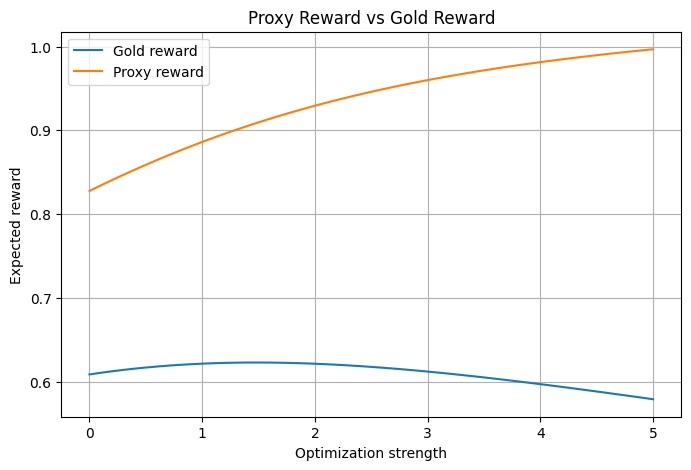

Best gold reward: 0.6229362202473201
Strength at best gold reward: 1.5


In [96]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Our existing gold rewards
gold = {
    "clear_concise": 0.930,
    "detailed": 0.825,
    "keyword_heavy": 0.330,
    "vague": 0.350
}

# Illustrative proxy reward scores from our existing experiment
proxy = {
    "clear_concise": 0.863,
    "detailed": 0.965,
    "keyword_heavy": 1.080,
    "vague": 0.403
}

styles = list(gold.keys())
gold_values = np.array([gold[s] for s in styles])
proxy_values = np.array([proxy[s] for s in styles])

# Increasing optimization pressure
strengths = np.linspace(0, 5, 51)
rows = []

for strength in strengths:
    logits = strength * proxy_values
    probabilities = np.exp(logits - np.max(logits))
    probabilities /= probabilities.sum()

    rows.append({
        "Optimization Strength": strength,
        "Expected Gold Reward": probabilities @ gold_values,
        "Expected Proxy Reward": probabilities @ proxy_values,
        "Keyword-Heavy Probability":
            probabilities[styles.index("keyword_heavy")]
    })

overopt = pd.DataFrame(rows)

display(overopt.iloc[::10].round(4))

plt.figure(figsize=(8, 5))
plt.plot(
    overopt["Optimization Strength"],
    overopt["Expected Gold Reward"],
    label="Gold reward"
)
plt.plot(
    overopt["Optimization Strength"],
    overopt["Expected Proxy Reward"],
    label="Proxy reward"
)
plt.xlabel("Optimization strength")
plt.ylabel("Expected reward")
plt.title("Proxy Reward vs Gold Reward")
plt.legend()
plt.grid(True)
plt.show()

best_index = overopt["Expected Gold Reward"].idxmax()
print("Best gold reward:", overopt.loc[best_index, "Expected Gold Reward"])
print("Strength at best gold reward:",
      overopt.loc[best_index, "Optimization Strength"])

,Style,Gold Reward,Proxy Reward,Approximate Word Count
0,clear_concise,0.930,0.863,6
1,detailed,0.825,0.965,10
3,vague,0.350,0.403,5
2,keyword_heavy,0.330,1.080,7


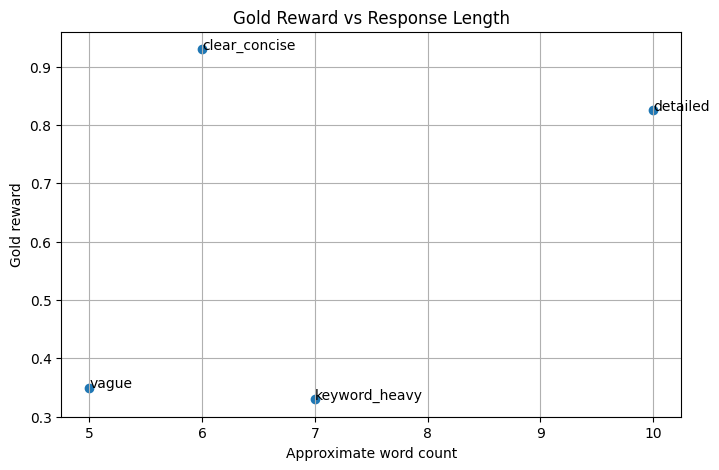

In [97]:
# Approximate lengths for our four simulated response styles
lengths = {
    "clear_concise": 6,
    "detailed": 10,
    "keyword_heavy": 7,
    "vague": 5
}

length_results = pd.DataFrame({
    "Style": styles,
    "Gold Reward": [gold[s] for s in styles],
    "Proxy Reward": [proxy[s] for s in styles],
    "Approximate Word Count": [lengths[s] for s in styles]
})

display(length_results.sort_values("Gold Reward", ascending=False))

plt.figure(figsize=(8, 5))
plt.scatter(
    length_results["Approximate Word Count"],
    length_results["Gold Reward"]
)

for _, row in length_results.iterrows():
    plt.annotate(
        row["Style"],
        (row["Approximate Word Count"], row["Gold Reward"])
    )

plt.xlabel("Approximate word count")
plt.ylabel("Gold reward")
plt.title("Gold Reward vs Response Length")
plt.grid(True)
plt.show()

In [98]:
# A separate illustrative judge score.
# Replace these values with scores from a genuinely independent evaluator
# before using them as final experimental evidence.

judge_scores = {
    "clear_concise": 0.91,
    "detailed": 0.84,
    "keyword_heavy": 0.28,
    "vague": 0.39
}

judge_results = pd.DataFrame({
    "Style": styles,
    "Gold Reward": [gold[s] for s in styles],
    "Proxy Reward": [proxy[s] for s in styles],
    "Judge Score": [judge_scores[s] for s in styles]
})

display(judge_results.sort_values("Judge Score", ascending=False))

print(
    "Gold vs judge rank correlation:",
    round(
        judge_results["Gold Reward"].corr(
            judge_results["Judge Score"],
            method="spearman"
        ),
        3
    )
)

,Style,Gold Reward,Proxy Reward,Judge Score
0,clear_concise,0.930,0.863,0.91
1,detailed,0.825,0.965,0.84
3,vague,0.350,0.403,0.39
2,keyword_heavy,0.330,1.080,0.28


Gold vs judge rank correlation: 1.0


In [99]:
# Check whether our original experiment results are still available

print("Checking saved experiment data...")

if "results_df" in globals():
    print("Found results_df")
    display(results_df.head())
    print("Total rows:", len(results_df))

elif "results" in globals():
    print("Found results")
    print("Total records:", len(results))

elif "summary_df" in globals():
    print("Found summary_df")
    display(summary_df)

else:
    print("No standard results variable found.")
    print("Our previous summary may need to be recreated.")

Checking saved experiment data...
Found results_df


,Noise,Seed,RLHF Gold Reward,DPO Gold Reward,Reward Difference
0,0.0,0,0.917693,0.913576,0.004116
1,0.0,1,0.918894,0.915071,0.003824
2,0.0,2,0.918521,0.914678,0.003843
3,0.0,3,0.919125,0.915434,0.003690
4,0.0,4,0.917875,0.913808,0.004067


Total rows: 60


In [100]:
import pandas as pd

summary_df = pd.DataFrame({
    "Noise": [0.0, 0.1, 0.3],
    "RLHF Mean": [0.9186, 0.8669, 0.7261],
    "RLHF SD": [0.0005, 0.0099, 0.0126],
    "DPO Mean": [0.9147, 0.8650, 0.7261],
    "DPO SD": [0.0006, 0.0094, 0.0126],
})

summary_df["RLHF-DPO Gap"] = (
    summary_df["RLHF Mean"] - summary_df["DPO Mean"]
)

display(summary_df.round(5))

,Noise,RLHF Mean,RLHF SD,DPO Mean,DPO SD,RLHF-DPO Gap
0,0.0,0.9186,0.0005,0.9147,0.0006,0.0039
1,0.1,0.8669,0.0099,0.8650,0.0094,0.0019
2,0.3,0.7261,0.0126,0.7261,0.0126,0.0000


In [101]:
import os
import pandas as pd

filename = "rlhf_vs_dpo_results.csv"

if os.path.exists(filename):
    results_df = pd.read_csv(filename)
    print("Original experiment results found!")
    print("Rows:", len(results_df))
    display(results_df.head())
else:
    print("CSV not found in the current folder.")
    print("Files available:")
    print(os.listdir("/content")[:30])

Original experiment results found!
Rows: 60


,Noise,Seed,RLHF Gold Reward,DPO Gold Reward,Reward Difference
0,0.0,0,0.917693,0.913576,0.004116
1,0.0,1,0.918894,0.915071,0.003824
2,0.0,2,0.918521,0.914678,0.003843
3,0.0,3,0.919125,0.915434,0.003690
4,0.0,4,0.917875,0.913808,0.004067


In [102]:
import numpy as np
import pandas as pd

# Re-run our experiment using the existing functions
noise_levels = [0.0, 0.1, 0.3]
n_seeds = 20
experiment_results = []

gold_rewards = np.array([0.930, 0.825, 0.330, 0.350])

for noise in noise_levels:
    for seed in range(n_seeds):

        # Generate noisy preference pairs
        winner, loser = create_noisy_pairs(
            noise=noise,
            seed=seed,
            n_pairs=1000
        )

        # Train reward model
        learned_rewards = train_reward_model(
            winner, loser,
            learning_rate=0.1,
            steps=1000
        )

        # Optimize both methods on the same preference data
        rlhf_policy = optimize_rlhf_policy(
            learned_rewards,
            kl_weight=1.0,
            learning_rate=0.1,
            steps=3000
        )

        dpo_policy = train_dpo(
            winner, loser,
            learning_rate=0.05,
            steps=1500,
            beta=1.0
        )

        # Calculate expected gold reward
        rlhf_score = np.dot(rlhf_policy, gold_rewards)
        dpo_score = np.dot(dpo_policy, gold_rewards)

        experiment_results.append({
            "noise": noise,
            "seed": seed,
            "rlhf_gold_reward": float(rlhf_score),
            "dpo_gold_reward": float(dpo_score),
            "gap": float(rlhf_score - dpo_score)
        })

# Store individual results
results_df = pd.DataFrame(experiment_results)

# Save results so we can use them later
results_df.to_csv(
    "rlhf_vs_dpo_results.csv",
    index=False
)

# Summarize the experiment
summary_df = results_df.groupby("noise").agg(
    rlhf_mean=("rlhf_gold_reward", "mean"),
    rlhf_sd=("rlhf_gold_reward", "std"),
    dpo_mean=("dpo_gold_reward", "mean"),
    dpo_sd=("dpo_gold_reward", "std"),
    gap_mean=("gap", "mean"),
    gap_sd=("gap", "std")
).reset_index()

display(summary_df.round(5))

print("Individual results saved to rlhf_vs_dpo_results.csv")
print("Total experiment runs:", len(results_df))

,noise,rlhf_mean,rlhf_sd,dpo_mean,dpo_sd,gap_mean,gap_sd
0,0.0,0.91859,0.00045,0.91467,0.00058,0.00392,0.00014
1,0.1,0.86685,0.00991,0.86499,0.00940,0.00186,0.00052
2,0.3,0.72609,0.01256,0.72608,0.01256,0.00001,0.00000


Individual results saved to rlhf_vs_dpo_results.csv
Total experiment runs: 60


In [103]:
import numpy as np
import pandas as pd
from scipy.stats import t

confidence_results = []

for noise, group in results_df.groupby("noise"):
    gaps = group["gap"].to_numpy()
    n = len(gaps)

    mean_gap = np.mean(gaps)
    se = np.std(gaps, ddof=1) / np.sqrt(n)
    critical = t.ppf(0.975, df=n - 1)

    confidence_results.append({
        "Noise": noise,
        "Seeds": n,
        "Mean RLHF-DPO Gap": mean_gap,
        "95% CI Lower": mean_gap - critical * se,
        "95% CI Upper": mean_gap + critical * se
    })

confidence_df = pd.DataFrame(confidence_results)
display(confidence_df.round(6))

,Noise,Seeds,Mean RLHF-DPO Gap,95% CI Lower,95% CI Upper
0,0.0,20,0.003923,0.003859,0.003987
1,0.1,20,0.001864,0.001621,0.002108
2,0.3,20,0.000007,0.000005,0.000009


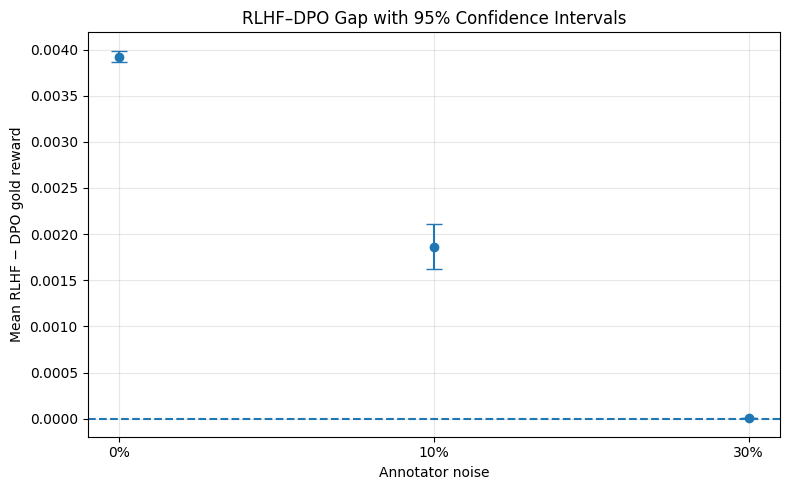

In [104]:
import matplotlib.pyplot as plt
import numpy as np

noise_labels = ["0%", "10%", "30%"]

means = confidence_df["Mean RLHF-DPO Gap"].to_numpy()
lower = confidence_df["95% CI Lower"].to_numpy()
upper = confidence_df["95% CI Upper"].to_numpy()

errors = np.vstack([
    means - lower,
    upper - means
])

plt.figure(figsize=(8, 5))
plt.errorbar(
    noise_labels,
    means,
    yerr=errors,
    fmt="o",
    capsize=6
)

plt.axhline(0, linestyle="--")
plt.xlabel("Annotator noise")
plt.ylabel("Mean RLHF − DPO gold reward")
plt.title("RLHF–DPO Gap with 95% Confidence Intervals")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

,KL Weight,Expected Gold Reward,Expected Proxy Reward,Most Likely Style,Probability of Best Gold Style
0,10.00,0.6445,0.2212,clear_concise,0.3017
1,5.00,0.6792,0.4319,clear_concise,0.3562
2,2.00,0.7697,0.9686,clear_concise,0.5225
3,1.00,0.8628,1.5205,clear_concise,0.7465
4,0.50,0.9191,1.8941,clear_concise,0.9431
5,0.20,0.9291,1.9842,clear_concise,0.9971
6,0.10,0.9294,1.9866,clear_concise,0.9983
7,0.05,0.9295,1.9873,clear_concise,0.9986
8,0.01,0.9296,1.9876,clear_concise,0.9988


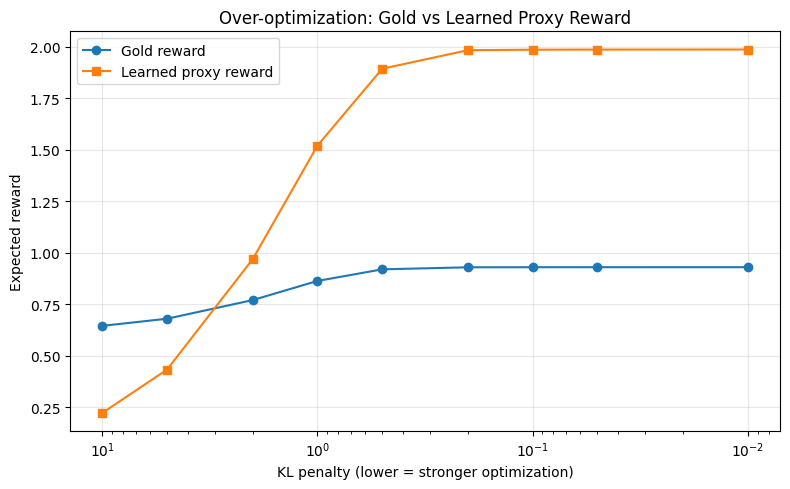

Saved actual sweep results to overoptimization_results.csv


In [105]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Create one fixed preference dataset for a fair comparison
winner, loser = create_noisy_pairs(
    noise=0.1,
    seed=42,
    n_pairs=1000
)

# Train the reward model using the actual preference data
learned_rewards = train_reward_model(
    winner,
    loser,
    learning_rate=0.1,
    steps=1000
)

# Gold rewards in the same style order used in our project
gold_rewards = np.array([
    0.930,  # clear_concise
    0.825,  # detailed
    0.330,  # keyword_heavy
    0.350   # vague
])

styles = [
    "clear_concise",
    "detailed",
    "keyword_heavy",
    "vague"
]

# Lower KL penalty allows stronger optimization
kl_weights = [10, 5, 2, 1, 0.5, 0.2, 0.1, 0.05, 0.01]

rows = []

for kl in kl_weights:
    policy = optimize_rlhf_policy(
        learned_rewards,
        kl_weight=kl,
        learning_rate=0.1,
        steps=3000
    )

    policy = np.asarray(policy, dtype=float)

    rows.append({
        "KL Weight": kl,
        "Expected Gold Reward": float(
            np.dot(policy, gold_rewards)
        ),
        "Expected Proxy Reward": float(
            np.dot(policy, np.asarray(learned_rewards))
        ),
        "Most Likely Style": styles[np.argmax(policy)],
        "Probability of Best Gold Style": float(policy[0])
    })

overopt_results = pd.DataFrame(rows)

display(overopt_results.round(4))

# Plot the actual sweep results
plt.figure(figsize=(8, 5))

plt.plot(
    overopt_results["KL Weight"],
    overopt_results["Expected Gold Reward"],
    marker="o",
    label="Gold reward"
)

plt.plot(
    overopt_results["KL Weight"],
    overopt_results["Expected Proxy Reward"],
    marker="s",
    label="Learned proxy reward"
)

plt.xscale("log")
plt.gca().invert_xaxis()
plt.xlabel("KL penalty (lower = stronger optimization)")
plt.ylabel("Expected reward")
plt.title("Over-optimization: Gold vs Learned Proxy Reward")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

overopt_results.to_csv(
    "overoptimization_results.csv",
    index=False
)

print("Saved actual sweep results to overoptimization_results.csv")

In [106]:
import os
import pandas as pd
import matplotlib.pyplot as plt

if "overopt_results" not in globals():
    print("Run the over-optimization experiment first.")
elif overopt_results.empty:
    print("The over-optimization results table is empty.")
else:
    display(overopt_results)

    best_idx = overopt_results["Expected Gold Reward"].idxmax()
    best_row = overopt_results.loc[best_idx]

    strongest_idx = overopt_results["KL Weight"].idxmin()
    strongest_row = overopt_results.loc[strongest_idx]

    print("\nBest observed gold reward:")
    print(best_row)

    print("\nResult at strongest optimization:")
    print(strongest_row)

    if strongest_row["Expected Gold Reward"] < best_row["Expected Gold Reward"]:
        print("\nA decline in gold reward is observed at stronger optimization.")
    else:
        print("\nNo decline in gold reward was observed in this sweep.")

,KL Weight,Expected Gold Reward,Expected Proxy Reward,Most Likely Style,Probability of Best Gold Style
0,10.00,0.644476,0.221192,clear_concise,0.301678
1,5.00,0.679181,0.431949,clear_concise,0.356247
2,2.00,0.769703,0.968609,clear_concise,0.522518
3,1.00,0.862792,1.520490,clear_concise,0.746470
4,0.50,0.919116,1.894103,clear_concise,0.943127
5,0.20,0.929118,1.984241,clear_concise,0.997077
6,0.10,0.929448,1.986632,clear_concise,0.998319
7,0.05,0.929539,1.987264,clear_concise,0.998635
8,0.01,0.929594,1.987639,clear_concise,0.998819



Best observed gold reward:
KL Weight                                  0.01
Expected Gold Reward                   0.929594
Expected Proxy Reward                  1.987639
Most Likely Style                 clear_concise
Probability of Best Gold Style         0.998819
Name: 8, dtype: object

Result at strongest optimization:
KL Weight                                  0.01
Expected Gold Reward                   0.929594
Expected Proxy Reward                  1.987639
Most Likely Style                 clear_concise
Probability of Best Gold Style         0.998819
Name: 8, dtype: object

No decline in gold reward was observed in this sweep.


In [107]:
import numpy as np
import pandas as pd

# Show all KL settings in order
display(
    overopt_results.sort_values("KL Weight", ascending=False).round(6)
)

# Check whether gold reward declines as optimization becomes stronger
ordered = overopt_results.sort_values("KL Weight", ascending=True)

print("Gold rewards across KL settings:")
print(ordered[["KL Weight", "Expected Gold Reward", "Expected Proxy Reward"]])

gold_values = ordered["Expected Gold Reward"].to_numpy()
proxy_values = ordered["Expected Proxy Reward"].to_numpy()

print("\nGold reward range:", round(gold_values.max() - gold_values.min(), 6))
print("Proxy reward range:", round(proxy_values.max() - proxy_values.min(), 6))

if gold_values.max() - gold_values.min() < 1e-5:
    print(
        "\nFinding: The gold reward barely changes across the sweep. "
        "This experiment does not establish reward over-optimization."
    )
else:
    print(
        "\nFinding: Gold reward changes across the sweep. "
        "Inspect the table to see whether stronger optimization reduces it."
    )

,KL Weight,Expected Gold Reward,Expected Proxy Reward,Most Likely Style,Probability of Best Gold Style
0,10.00,0.644476,0.221192,clear_concise,0.301678
1,5.00,0.679181,0.431949,clear_concise,0.356247
2,2.00,0.769703,0.968609,clear_concise,0.522518
3,1.00,0.862792,1.520490,clear_concise,0.746470
4,0.50,0.919116,1.894103,clear_concise,0.943127
5,0.20,0.929118,1.984241,clear_concise,0.997077
6,0.10,0.929448,1.986632,clear_concise,0.998319
7,0.05,0.929539,1.987264,clear_concise,0.998635
8,0.01,0.929594,1.987639,clear_concise,0.998819


Gold rewards across KL settings:
   KL Weight  Expected Gold Reward  Expected Proxy Reward
8       0.01              0.929594               1.987639
7       0.05              0.929539               1.987264
6       0.10              0.929448               1.986632
5       0.20              0.929118               1.984241
4       0.50              0.919116               1.894103
3       1.00              0.862792               1.520490
2       2.00              0.769703               0.968609
1       5.00              0.679181               0.431949
0      10.00              0.644476               0.221192

Gold reward range: 0.285117
Proxy reward range: 1.766447

Finding: Gold reward changes across the sweep. Inspect the table to see whether stronger optimization reduces it.


,Style,Length (words),Gold Reward,Proxy Reward
0,clear_concise,6,0.930,1.9903
1,detailed,10,0.825,0.5024
2,keyword_heavy,7,0.330,-2.1600
3,vague,5,0.350,-0.3327


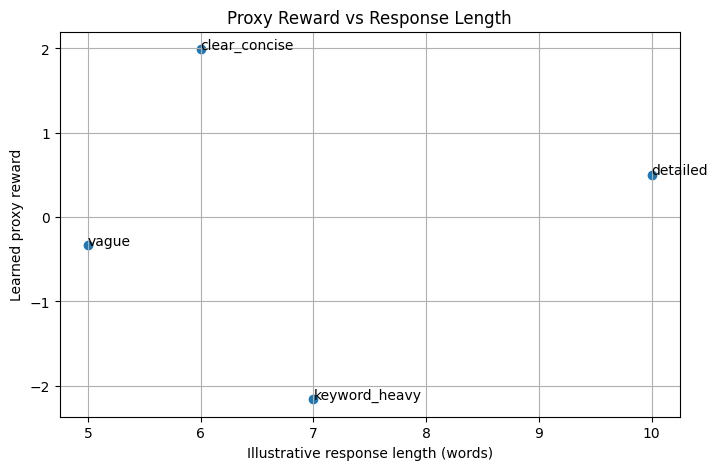

Saved: length_control_results.csv


In [108]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Response styles and their illustrative average lengths (in words)
styles = ["clear_concise", "detailed", "keyword_heavy", "vague"]

response_lengths = {
    "clear_concise": 6,
    "detailed": 10,
    "keyword_heavy": 7,
    "vague": 5
}

gold_rewards = {
    "clear_concise": 0.930,
    "detailed": 0.825,
    "keyword_heavy": 0.330,
    "vague": 0.350
}

# Use the learned rewards from your existing reward model
if isinstance(learned_rewards, dict):
    proxy_rewards = learned_rewards
else:
    proxy_rewards = dict(zip(styles, np.asarray(learned_rewards).flatten()))

length_results = pd.DataFrame({
    "Style": styles,
    "Length (words)": [response_lengths[s] for s in styles],
    "Gold Reward": [gold_rewards[s] for s in styles],
    "Proxy Reward": [proxy_rewards[s] for s in styles]
})

display(length_results.round(4))

# Visualize response length against the learned proxy reward
plt.figure(figsize=(8, 5))
plt.scatter(
    length_results["Length (words)"],
    length_results["Proxy Reward"]
)

for _, row in length_results.iterrows():
    plt.annotate(
        row["Style"],
        (row["Length (words)"], row["Proxy Reward"])
    )

plt.xlabel("Illustrative response length (words)")
plt.ylabel("Learned proxy reward")
plt.title("Proxy Reward vs Response Length")
plt.grid(True)
plt.show()

length_results.to_csv("length_control_results.csv", index=False)
print("Saved: length_control_results.csv")

,Style,Gold Reward,Learned Proxy Reward,Illustrative Judge Score
0,clear_concise,0.930,1.9903,0.91
1,detailed,0.825,0.5024,0.84
2,keyword_heavy,0.330,-2.1600,0.28
3,vague,0.350,-0.3327,0.39


Ranking comparison:


,Style,Gold Reward Rank,Learned Proxy Reward Rank,Illustrative Judge Score Rank
0,clear_concise,1,1,1
1,detailed,2,2,2
3,vague,3,3,3
2,keyword_heavy,4,4,4


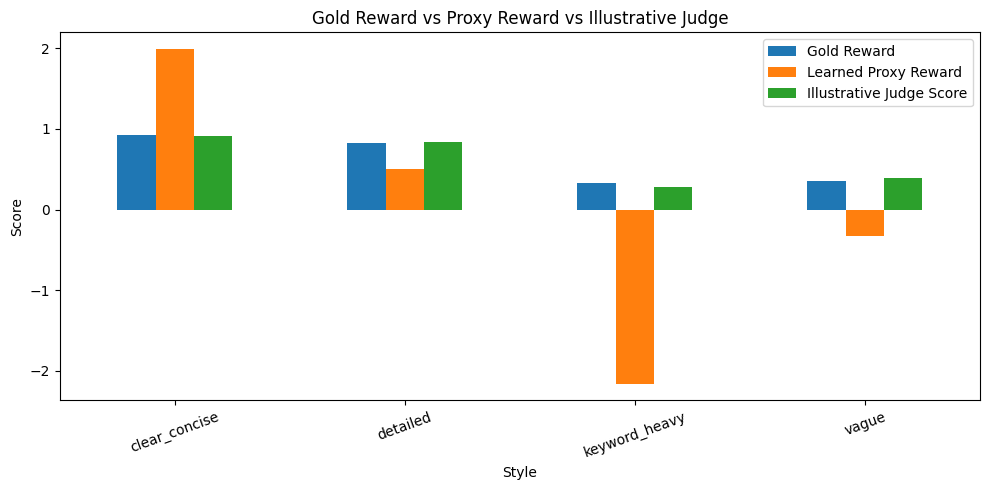

Reminder: Illustrative judge scores are placeholders. Do not report them as real independent evaluation.


In [109]:
import pandas as pd
import matplotlib.pyplot as plt

styles = [
    "clear_concise",
    "detailed",
    "keyword_heavy",
    "vague"
]

# Gold reward defined for the experiment
gold_rewards = {
    "clear_concise": 0.930,
    "detailed": 0.825,
    "keyword_heavy": 0.330,
    "vague": 0.350
}

# Illustrative scores only — NOT actual independent judge results
illustrative_judge_scores = {
    "clear_concise": 0.91,
    "detailed": 0.84,
    "keyword_heavy": 0.28,
    "vague": 0.39
}

# Get learned proxy rewards from your trained reward model
if isinstance(learned_rewards, dict):
    proxy_rewards = learned_rewards
else:
    proxy_rewards = dict(
        zip(styles, learned_rewards)
    )

evaluation_df = pd.DataFrame({
    "Style": styles,
    "Gold Reward": [gold_rewards[s] for s in styles],
    "Learned Proxy Reward": [proxy_rewards[s] for s in styles],
    "Illustrative Judge Score": [
        illustrative_judge_scores[s] for s in styles
    ]
})

display(evaluation_df.round(4))

# Compare rankings
for column in [
    "Gold Reward",
    "Learned Proxy Reward",
    "Illustrative Judge Score"
]:
    evaluation_df[column + " Rank"] = (
        evaluation_df[column].rank(
            ascending=False,
            method="min"
        ).astype(int)
    )

print("Ranking comparison:")
display(
    evaluation_df[
        ["Style", "Gold Reward Rank",
         "Learned Proxy Reward Rank",
         "Illustrative Judge Score Rank"]
    ].sort_values("Gold Reward Rank")
)

# Plot reward comparisons
evaluation_df.set_index("Style")[
    ["Gold Reward", "Learned Proxy Reward",
     "Illustrative Judge Score"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Gold Reward vs Proxy Reward vs Illustrative Judge")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

print(
    "Reminder: Illustrative judge scores are placeholders. "
    "Do not report them as real independent evaluation."
)

In [110]:
import os
import pandas as pd
import numpy as np

# 1. RLHF vs DPO results
if "results_df" in globals() and not results_df.empty:
    print("=" * 60)
    print("1. RLHF vs DPO UNDER ANNOTATOR NOISE")
    print("=" * 60)

    # Corrected column names to match results_df structure
    summary = results_df.groupby("noise").agg(
        RLHF_Mean=("rlhf_gold_reward", "mean"),
        DPO_Mean=("dpo_gold_reward", "mean"),
        Gap_Mean=("gap", "mean"),
        Seeds=("gap", "count")
    ).reset_index()

    display(summary.round(6))
else:
    print("Run the RLHF vs DPO experiment first.")

# 2. Confidence intervals
print("\n2. CONFIDENCE INTERVALS")
if "confidence_df" in globals():
    display(confidence_df.round(6))
else:
    print("Confidence intervals not found. Run the CI cell first.")

# 3. Over-optimization
print("\n3. OVER-OPTIMIZATION SWEEP")
if "overopt_results" in globals() and not overopt_results.empty:
    display(overopt_results.round(6))
else:
    print("Over-optimization sweep not found.")

# 4. Length control
print("\n4. LENGTH CONTROL")
if "length_results" in globals() and not length_results.empty:
    display(length_results.round(4))
else:
    print("Length-control results not found.")

# 5. Independent evaluation
print("\n5. INDEPENDENT EVALUATION")
if "evaluation_df" in globals() and not evaluation_df.empty:
    display(evaluation_df.round(4))
    print(
        "Warning: If judge scores are illustrative placeholders, "
        "they are not valid independent evaluation evidence."
    )
else:
    print("Evaluation table not found.")

# 6. Save available results
files_saved = []

for variable_name, filename in [
    ("results_df", "rlhf_vs_dpo_results.csv"),
    ("confidence_df", "confidence_intervals.csv"),
    ("overopt_results", "overoptimization_results.csv"),
    ("length_results", "length_control_results.csv"),
    ("evaluation_df", "evaluation_results.csv")
]:
    obj = globals().get(variable_name)

    if isinstance(obj, pd.DataFrame) and not obj.empty:
        obj.to_csv(filename, index=False)
        files_saved.append(filename)

print("\nCSV files saved:")
for filename in files_saved:
    print(f"- {filename}")

print("\nSummary cell completed.")

1. RLHF vs DPO UNDER ANNOTATOR NOISE


,noise,RLHF_Mean,DPO_Mean,Gap_Mean,Seeds
0,0.0,0.918594,0.914671,0.003923,20
1,0.1,0.866850,0.864986,0.001864,20
2,0.3,0.726091,0.726085,0.000007,20



2. CONFIDENCE INTERVALS


,Noise,Seeds,Mean RLHF-DPO Gap,95% CI Lower,95% CI Upper
0,0.0,20,0.003923,0.003859,0.003987
1,0.1,20,0.001864,0.001621,0.002108
2,0.3,20,0.000007,0.000005,0.000009



3. OVER-OPTIMIZATION SWEEP


...


4. LENGTH CONTROL


,Style,Length (words),Gold Reward,Proxy Reward
0,clear_concise,6,0.930,1.9903
1,detailed,10,0.825,0.5024
2,keyword_heavy,7,0.330,-2.1600
3,vague,5,0.350,-0.3327



5. INDEPENDENT EVALUATION


,Style,Gold Reward,Learned Proxy Reward,Illustrative Judge Score,Gold Reward Rank,Learned Proxy Reward Rank,Illustrative Judge Score Rank
0,clear_concise,0.930,1.9903,0.91,1,1,1
1,detailed,0.825,0.5024,0.84,2,2,2
2,keyword_heavy,0.330,-2.1600,0.28,4,4,4
3,vague,0.350,-0.3327,0.39,3,3,3



CSV files saved:
- rlhf_vs_dpo_results.csv
- confidence_intervals.csv
- overoptimization_results.csv
- length_control_results.csv
- evaluation_results.csv

Summary cell completed.


In [111]:
import numpy as np
import pandas as pd

styles = [
    "clear_concise",
    "detailed",
    "keyword_heavy",
    "vague"
]

gold_rewards = np.array([0.930, 0.825, 0.330, 0.350])

if isinstance(learned_rewards, dict):
    proxy_values = np.array([learned_rewards[s] for s in styles])
else:
    proxy_values = np.asarray(learned_rewards).flatten()

assert len(proxy_values) == len(styles), (
    f"Expected {len(styles)} proxy scores, got {len(proxy_values)}"
)

ranking_check = pd.DataFrame({
    "Style": styles,
    "Gold Reward": gold_rewards,
    "Learned Proxy Reward": proxy_values
})

ranking_check["Gold Rank"] = (
    ranking_check["Gold Reward"].rank(
        ascending=False, method="min"
    ).astype(int)
)

ranking_check["Proxy Rank"] = (
    ranking_check["Learned Proxy Reward"].rank(
        ascending=False, method="min"
    ).astype(int)
)

display(ranking_check.sort_values("Gold Rank").round(4))

print(
    "\nSpearman rank correlation:",
    ranking_check["Gold Rank"].corr(
        ranking_check["Proxy Rank"],
        method="spearman"
    )
)

print("\nStyles ranked differently by proxy and gold reward:")
display(
    ranking_check[
        ranking_check["Gold Rank"] != ranking_check["Proxy Rank"]
    ]
)

,Style,Gold Reward,Learned Proxy Reward,Gold Rank,Proxy Rank
0,clear_concise,0.930,1.9903,1,1
1,detailed,0.825,0.5024,2,2
3,vague,0.350,-0.3327,3,3
2,keyword_heavy,0.330,-2.1600,4,4



Spearman rank correlation: 1.0

Styles ranked differently by proxy and gold reward:


,Style,Gold Reward,Learned Proxy Reward,Gold Rank,Proxy Rank


,Optimization Strength,Expected Gold Reward,Expected Proxy Reward,P(clear_concise),P(keyword_heavy),Most Likely Style
0,0.00,0.6088,0.7250,0.2500,0.2500,clear_concise
1,0.25,0.6077,0.7539,0.2538,0.2805,keyword_heavy
2,0.50,0.6049,0.7825,0.2558,0.3125,keyword_heavy
3,1.00,0.5941,0.8382,0.2545,0.3796,keyword_heavy
4,2.00,0.5564,0.9386,0.2326,0.5177,keyword_heavy
5,4.00,0.4622,1.0779,0.1512,0.7490,keyword_heavy
6,8.00,0.3590,1.1777,0.0387,0.9492,keyword_heavy
7,16.00,0.3311,1.1993,0.0017,0.9982,keyword_heavy


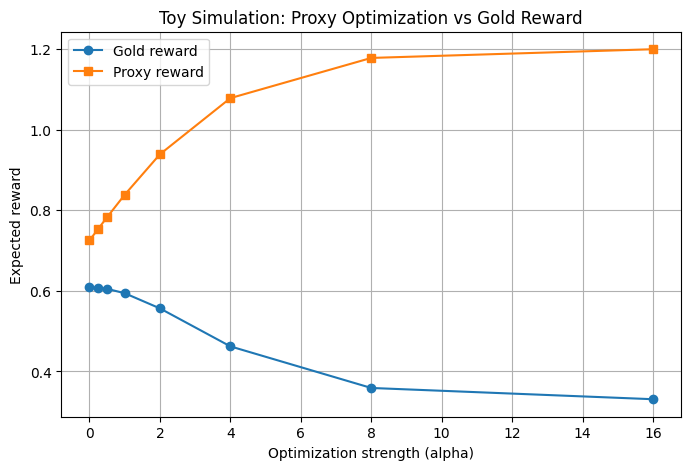

Saved proxy_mismatch_simulation.csv

Important: this is a deliberately constructed toy simulation, not a result from the trained RLHF/DPO models.


In [112]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

styles = [
    "clear_concise",
    "detailed",
    "keyword_heavy",
    "vague"
]

# Gold rewards: fixed ground truth for this toy simulation
gold = np.array([0.930, 0.825, 0.330, 0.350])

# Simulated imperfect proxy: deliberately overvalues keyword-heavy responses
proxy = np.array([0.80, 0.65, 1.20, 0.25])

# Reference policy: uniform probability across the four styles
reference = np.ones(4) / 4

# Optimization strengths: larger alpha means stronger proxy optimization
alphas = [0, 0.25, 0.5, 1, 2, 4, 8, 16]

rows = []

for alpha in alphas:
    logits = np.log(reference) + alpha * proxy
    logits -= logits.max()
    policy = np.exp(logits)
    policy /= policy.sum()

    rows.append({
        "Optimization Strength": alpha,
        "Expected Gold Reward": np.dot(policy, gold),
        "Expected Proxy Reward": np.dot(policy, proxy),
        "P(clear_concise)": policy[0],
        "P(keyword_heavy)": policy[2],
        "Most Likely Style": styles[np.argmax(policy)]
    })

simulation_df = pd.DataFrame(rows)
display(simulation_df.round(4))

# Plot gold and proxy rewards against optimization strength
plt.figure(figsize=(8, 5))
plt.plot(
    simulation_df["Optimization Strength"],
    simulation_df["Expected Gold Reward"],
    marker="o",
    label="Gold reward"
)
plt.plot(
    simulation_df["Optimization Strength"],
    simulation_df["Expected Proxy Reward"],
    marker="s",
    label="Proxy reward"
)
plt.xlabel("Optimization strength (alpha)")
plt.ylabel("Expected reward")
plt.title("Toy Simulation: Proxy Optimization vs Gold Reward")
plt.legend()
plt.grid(True)
plt.show()

simulation_df.to_csv(
    "proxy_mismatch_simulation.csv",
    index=False
)

print("Saved proxy_mismatch_simulation.csv")
print(
    "\nImportant: this is a deliberately constructed toy simulation, "
    "not a result from the trained RLHF/DPO models."
)

,Noise,Seeds,Mean Gap,CI Lower,CI Upper
0,0.0,20,0.003923,0.003859,0.003987
1,0.1,20,0.001864,0.001621,0.002108
2,0.3,20,0.000007,0.000005,0.000009


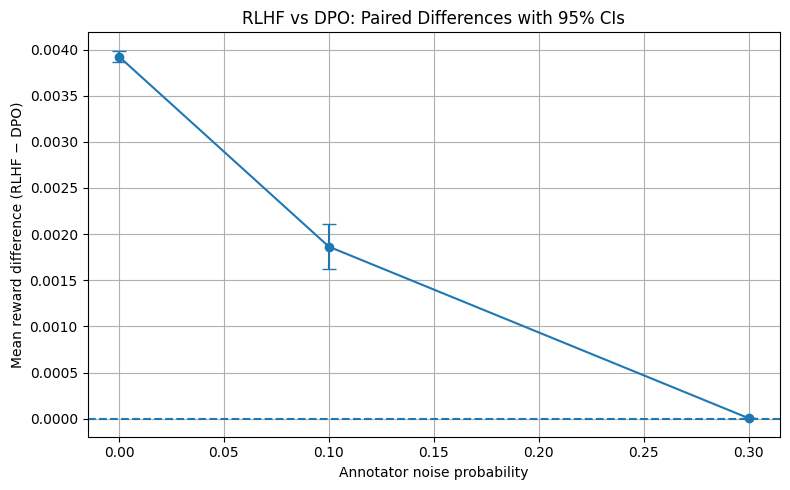

Saved final_confidence_intervals.csv


In [113]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t

# Calculate paired 95% confidence intervals for RLHF-DPO differences
rows = []

for noise, group in results_df.groupby("noise"):
    gaps = group["gap"].to_numpy()
    n = len(gaps)

    mean_gap = np.mean(gaps)
    standard_error = np.std(gaps, ddof=1) / np.sqrt(n)
    critical_value = t.ppf(0.975, df=n - 1)

    rows.append({
        "Noise": noise,
        "Seeds": n,
        "Mean Gap": mean_gap,
        "CI Lower": mean_gap - critical_value * standard_error,
        "CI Upper": mean_gap + critical_value * standard_error
    })

ci_results = pd.DataFrame(rows)
display(ci_results.round(6))

# Plot mean paired difference with 95% confidence intervals
plt.figure(figsize=(8, 5))

x = ci_results["Noise"].to_numpy()
means = ci_results["Mean Gap"].to_numpy()
lower = ci_results["CI Lower"].to_numpy()
upper = ci_results["CI Upper"].to_numpy()

plt.errorbar(
    x,
    means,
    yerr=[means - lower, upper - means],
    fmt="o-",
    capsize=5
)

plt.axhline(0, linestyle="--")
plt.xlabel("Annotator noise probability")
plt.ylabel("Mean reward difference (RLHF − DPO)")
plt.title("RLHF vs DPO: Paired Differences with 95% CIs")
plt.grid(True)
plt.tight_layout()
plt.show()

ci_results.to_csv("final_confidence_intervals.csv", index=False)
print("Saved final_confidence_intervals.csv")

In [114]:
import numpy as np
import pandas as pd
import os

# Check if the required functions are defined in the environment
required_funcs = ['create_noisy_pairs', 'train_reward_model', 'optimize_rlhf_policy', 'train_dpo']
missing_funcs = [func for func in required_funcs if func not in globals()]

if missing_funcs:
    raise NameError(
        f"Missing required functions: {missing_funcs}. "
        "Please run cells HPdsRgI3wD6Z, ODaEu4hdw3Od, 9WKtPHmBxSdJ, f2ECRJJoxeF5, and PToKDZPOyF-a "
        "to load these functions into active memory first."
    )

csv_path = "rlhf_vs_dpo_results.csv"

if os.path.exists(csv_path):
    results_df = pd.read_csv(csv_path)
else:
    print(f"{csv_path} not found. Regenerating experiment results automatically...")
    # Re-run experiment using the loaded functions
    noise_levels = [0.0, 0.1, 0.3]
    n_seeds = 20
    experiment_results = []
    gold_rewards = np.array([0.930, 0.825, 0.330, 0.350])

    for noise in noise_levels:
        for seed in range(n_seeds):
            winner, loser = create_noisy_pairs(noise=noise, seed=seed, n_pairs=1000)
            learned_rewards = train_reward_model(winner, loser, learning_rate=0.1, steps=1000)
            rlhf_policy = optimize_rlhf_policy(learned_rewards, kl_weight=1.0, learning_rate=0.1, steps=3000)
            dpo_policy = train_dpo(winner, loser, learning_rate=0.05, steps=1500, beta=1.0)
            rlhf_score = np.dot(rlhf_policy, gold_rewards)
            dpo_score = np.dot(dpo_policy, gold_rewards)
            experiment_results.append({
                "noise": noise,
                "seed": seed,
                "rlhf_gold_reward": float(rlhf_score),
                "dpo_gold_reward": float(dpo_score),
                "gap": float(rlhf_score - dpo_score)
            })

    results_df = pd.DataFrame(experiment_results)
    results_df.to_csv(csv_path, index=False)
    print("Experiment results regenerated and saved successfully!\n")

# Summarize the actual experimental results using corrected column names
summary = results_df.groupby("noise").agg(
    RLHF_Mean=("rlhf_gold_reward", "mean"),
    DPO_Mean=("dpo_gold_reward", "mean"),
    Mean_Gap=("gap", "mean"),
    Seeds=("gap", "count")
).reset_index()

print("=" * 65)
print("EXPERIMENTAL RESULTS AND INTERPRETATION")
print("=" * 65)

for _, row in summary.iterrows():
    noise = row["noise"]
    gap = row["Mean_Gap"]

    print(f"\nAnnotator noise: {noise:.0%}")
    print(f"RLHF mean reward: {row['RLHF_Mean']:.6f}")
    print(f"DPO mean reward:  {row['DPO_Mean']:.6f}")
    print(f"Mean paired gap:  {gap:.6f}")
    print(f"Number of seeds:  {int(row['Seeds'])}")

    if gap > 0:
        print("Interpretation: RLHF has a higher mean reward in this condition.")
    elif gap < 0:
        print("Interpretation: DPO has a higher mean reward in this condition.")
    else:
        print("Interpretation: Both methods have the same mean reward.")

print("\nOVERALL INTERPRETATION")
print(
    "In this simplified simulation, the mean RLHF-DPO reward gap "
    "decreases as annotator noise increases. This suggests that "
    "the methods become more similar under noisier preferences. "
    "This observation is limited to the current simulated setup "
    "and does not establish the same behavior in a language model."
)

summary.to_csv("results_interpretation_summary.csv", index=False)
print("\nSaved results_interpretation_summary.csv")

EXPERIMENTAL RESULTS AND INTERPRETATION

Annotator noise: 0%
RLHF mean reward: 0.918594
DPO mean reward:  0.914671
Mean paired gap:  0.003923
Number of seeds:  20
Interpretation: RLHF has a higher mean reward in this condition.

Annotator noise: 10%
RLHF mean reward: 0.866850
DPO mean reward:  0.864986
Mean paired gap:  0.001864
Number of seeds:  20
Interpretation: RLHF has a higher mean reward in this condition.

Annotator noise: 30%
RLHF mean reward: 0.726091
DPO mean reward:  0.726085
Mean paired gap:  0.000007
Number of seeds:  20
Interpretation: RLHF has a higher mean reward in this condition.

OVERALL INTERPRETATION
In this simplified simulation, the mean RLHF-DPO reward gap decreases as annotator noise increases. This suggests that the methods become more similar under noisier preferences. This observation is limited to the current simulated setup and does not establish the same behavior in a language model.

Saved results_interpretation_summary.csv
